# Multilingual Spam Email Detection (English + Bangla)

QLoRA fine-tuning of `Phi-3-mini-4k-instruct` for binary spam/ham classification on a combined **English** (SMS Spam Collection) + **Bangla** (phishing/spam) dataset.

# STEP 1 — INSTALL
Hugging Face ecosystem and LoRA tools.

In [ ]:
!pip install -q torch transformers datasets peft accelerate bitsandbytes scikit-learn pandas

In [1]:
!pip install wordcloud

# STEP 2 — IMPORTS

In [16]:
import torch
import gc
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from wordcloud import WordCloud
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from datasets import Dataset

### Hugging Face Authentication

To avoid warnings about unauthenticated requests and enable higher rate limits/faster downloads from the Hugging Face Hub, you can provide an authentication token. You can obtain a token from your Hugging Face profile settings.

**Steps to set up your HF Token in Colab:**
1. Go to your Hugging Face profile settings: `https://huggingface.co/settings/tokens`.
2. Create a new token with 'read' access (or 'write' if you plan to push models).
3. In Colab, click the '🔑' icon (Secrets) in the left sidebar.
4. Add a new secret named `HF_TOKEN` and paste your Hugging Face token as its value.
5. Ensure 'Notebook access' is toggled on for this secret.

The following cell will then use this token to log you in.

In [ ]:
from huggingface_hub import login
from google.colab import userdata

# Retrieve HF_TOKEN from Colab secrets
hf_token = userdata.get('HF_TOKEN')

if hf_token:
    login(token=hf_token)
    print("Successfully logged in to Hugging Face Hub.")
else:
    print("HF_TOKEN not found in Colab secrets. Proceeding with unauthenticated requests.")

Successfully logged in to Hugging Face Hub.


# STEP 3 — LOAD DATASETS (English + Bangla)
English SMS Spam Collection + the Bangla phishing/spam dataset you uploaded. No manual regex cleaning here — an LLM-based classifier reads raw text directly in either language, and hand-writing cleaning rules for Bangla script would be its own project.

In [17]:
# --- English: SMS Spam Collection (ham/spam) ---
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
urllib.request.urlretrieve(url, "spam.tsv")

df_en = pd.read_csv("spam.tsv", sep="\t", header=None)
df_en.columns = ["Category", "Message"]
df_en = df_en.rename(columns={"Message": "text"})
df_en["label"] = df_en["Category"].map({"ham": 0, "spam": 1})
df_en["lang"] = "en"
df_en = df_en[["text", "label", "lang"]]

# --- Bangla: phishing/spam dataset (already 0 = legit/ham, 1 = phishing+promo/spam) ---
bangla_path = "bangla_spam_detection_dataset.csv"
if not os.path.exists(bangla_path):
    try:
        from google.colab import files
        print(f"Please upload {bangla_path}:")
        uploaded = files.upload()
        bangla_path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"'{bangla_path}' not found. Upload it to the working directory "
            "(or run this in Colab, where you'll be prompted)."
        )

df_bn_raw = pd.read_csv(bangla_path)
# keep template_id for a leakage-safe split in STEP 4, drop it before training
df_bn = df_bn_raw[["text", "label", "template_id"]].copy()
df_bn["lang"] = "bn"

print(f"English : {len(df_en):5d} rows  |  ham={sum(df_en['label']==0)}  spam={sum(df_en['label']==1)}")
print(f"Bangla  : {len(df_bn):5d} rows  |  ham={sum(df_bn['label']==0)}  spam={sum(df_bn['label']==1)}")
print(f"Combined: {len(df_en) + len(df_bn):5d} rows")

English :  5572 rows  |  ham=4825  spam=747
Bangla  :  3114 rows  |  ham=1443  spam=1671
Combined:  8686 rows


In [5]:
# ====================================================
# SECTION 3.1 : SANITY CHECK
# ====================================================

import pandas as pd
import numpy as np

print("="*60)
print("ENGLISH DATASET")
print("="*60)

print(df_en.head())

print("\nShape :", df_en.shape)

print("\nColumns")
print(df_en.columns)

print("\nData Types")
print(df_en.dtypes)

print("\nMissing Values")
print(df_en.isnull().sum())

print("\nDuplicate Rows :", df_en.duplicated().sum())

print("\nUnique Labels")
print(df_en["label"].value_counts())


print("\n\n")

print("="*60)
print("BANGLA DATASET")
print("="*60)

print(df_bn.head())

print("\nShape :", df_bn.shape)

print("\nColumns")
print(df_bn.columns)

print("\nData Types")
print(df_bn.dtypes)

print("\nMissing Values")
print(df_bn.isnull().sum())

print("\nDuplicate Rows :", df_bn.duplicated().sum())

print("\nUnique Labels")
print(df_bn["label"].value_counts())

ENGLISH DATASET
                                                text  label lang
0  Go until jurong point, crazy.. Available only ...      0   en
1                      Ok lar... Joking wif u oni...      0   en
2  Free entry in 2 a wkly comp to win FA Cup fina...      1   en
3  U dun say so early hor... U c already then say...      0   en
4  Nah I don't think he goes to usf, he lives aro...      0   en

Shape : (5572, 3)

Columns
Index(['text', 'label', 'lang'], dtype='object')

Data Types
text     object
label     int64
lang     object
dtype: object

Missing Values
text     0
label    0
lang     0
dtype: int64

Duplicate Rows : 403

Unique Labels
label
0    4825
1     747
Name: count, dtype: int64



BANGLA DATASET
                                                text  label  template_id lang
0  Subject: আপনি ১ লাখ টাকা জিতেছেন!\n\nআপনার মোব...      1            0   bn
1    আপনার পার্সেল ট্র্যাকিং নম্বর: PK14165 – Pathao      0            1   bn
2  অবিলম্বে আপনার পাসওয়ার্ড রিসেট করুন!

In [6]:
# ====================================================
# SECTION 3.2 : MISSING VALUE TREATMENT
# ====================================================

print("="*60)
print("Before Cleaning")
print("="*60)

print(df_en.isnull().sum())
print(df_bn.isnull().sum())

# English
df_en = df_en.dropna(subset=["text","label"])

# Bangla
df_bn = df_bn.dropna(subset=["text","label"])

print("\n")

print("="*60)
print("After Cleaning")
print("="*60)

print(df_en.isnull().sum())
print(df_bn.isnull().sum())

Before Cleaning
text     0
label    0
lang     0
dtype: int64
text           0
label          0
template_id    0
lang           0
dtype: int64


After Cleaning
text     0
label    0
lang     0
dtype: int64
text           0
label          0
template_id    0
lang           0
dtype: int64


In [7]:
# ====================================================
# SECTION 3.3 : DUPLICATE REMOVAL
# ====================================================

print("Before")

print("English :",len(df_en))

print("Bangla :",len(df_bn))

# Remove duplicate emails/messages only based on text

df_en = df_en.drop_duplicates(subset=["text"]).reset_index(drop=True)

df_bn = df_bn.drop_duplicates(subset=["text"]).reset_index(drop=True)

print()

print("After")

print("English :",len(df_en))

print("Bangla :",len(df_bn))

Before
English : 5572
Bangla : 3114

After
English : 5169
Bangla : 3114


In [ ]:
# ====================================================
# SECTION 3.4 : GARBAGE VALUE TREATMENT
# ====================================================

import re

def clean_text(text):

    text=str(text)

    text=text.replace("\n"," ")

    text=text.replace("\t"," ")

    text=text.replace("\r"," ")

    text=re.sub(r"\s+"," ",text)

    text=text.strip()

    return text

df_en["text"]=df_en["text"].apply(clean_text)

df_bn["text"]=df_bn["text"].apply(clean_text)

print(df_en.head())

print(df_bn.head())

                                                text  label lang
0  Go until jurong point, crazy.. Available only ...      0   en
1                      Ok lar... Joking wif u oni...      0   en
2  Free entry in 2 a wkly comp to win FA Cup fina...      1   en
3  U dun say so early hor... U c already then say...      0   en
4  Nah I don't think he goes to usf, he lives aro...      0   en
                                                text  label  template_id lang
0  Subject: আপনি ১ লাখ টাকা জিতেছেন! আপনার মোবাইল...      1            0   bn
1    আপনার পার্সেল ট্র্যাকিং নম্বর: PK14165 – Pathao      0            1   bn
2  অবিলম্বে আপনার পাসওয়ার্ড রিসেট করুন! https://...      1            2   bn
3  Subject: আপনার অর্ডার নিশ্চিত হয়েছে আপনার অর্...      0            3   bn
4  Eid স্পেশাল গিফট পেয়েছেন! ক্লেইম করতে ক্লিক ক...      1            4   bn


In [13]:
# ====================================================
# SECTION 3.5 : NORMALIZATION
# ====================================================

import unicodedata
import re

def normalize_text(text):

    text = unicodedata.normalize("NFKC", text)

    text = text.lower()

    text = re.sub(r"http\S+"," URL ",text)

    text = re.sub(r"www\S+"," URL ",text)

    text = re.sub(r"\d+"," NUMBER ",text)

    text = re.sub(r"\s+"," ",text)

    return text.strip()

df_en["text"] = df_en["text"].apply(normalize_text)

df_bn["text"] = df_bn["text"].apply(normalize_text)

print(df_en.head())

print(df_bn.head())

                                                text  label lang
0  go until jurong point, crazy.. available only ...      0   en
1                      ok lar... joking wif u oni...      0   en
2  free entry in NUMBER a wkly comp to win fa cup...      1   en
3  u dun say so early hor... u c already then say...      0   en
4  nah i don't think he goes to usf, he lives aro...      0   en
                                                text  label  template_id lang
0  subject: আপনি NUMBER লাখ টাকা জিতেছেন! আপনার ম...      1            0   bn
1  আপনার পার্সেল ট্র্যাকিং নম্বর: pk NUMBER – pathao      0            1   bn
2          অবিলম্বে আপনার পাসওয়ার্ড রিসেট করুন! URL      1            2   bn
3  subject: আপনার অর্ডার নিশ্চিত হয়েছে আপনার অর্...      0            3   bn
4  eid স্পেশাল গিফট পেয়েছেন! ক্লেইম করতে ক্লিক ক...      1            4   bn


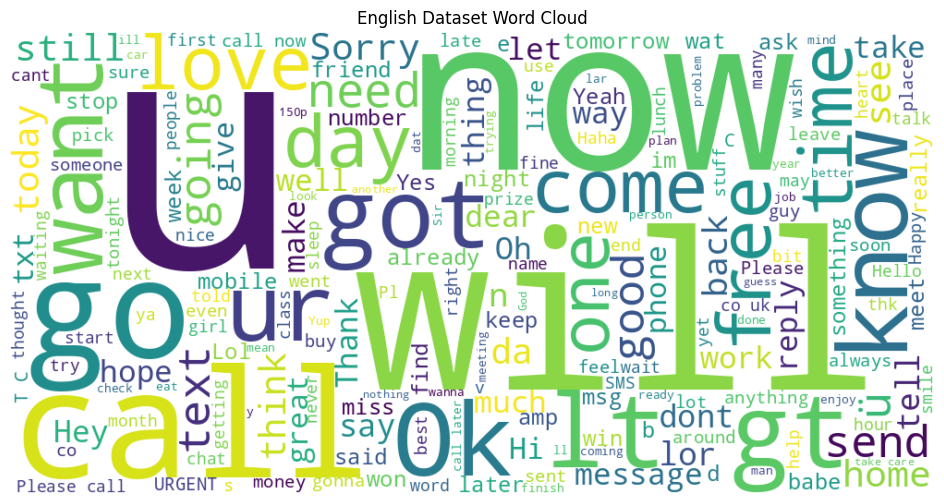

In [5]:
# ====================================================
# SECTION 3.6 : ENGLISH WORD CLOUD
# ====================================================

english_text = " ".join(df_en["text"].astype(str))

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=200
).generate(english_text)

plt.figure(figsize=(15,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("English Dataset Word Cloud")
plt.show()

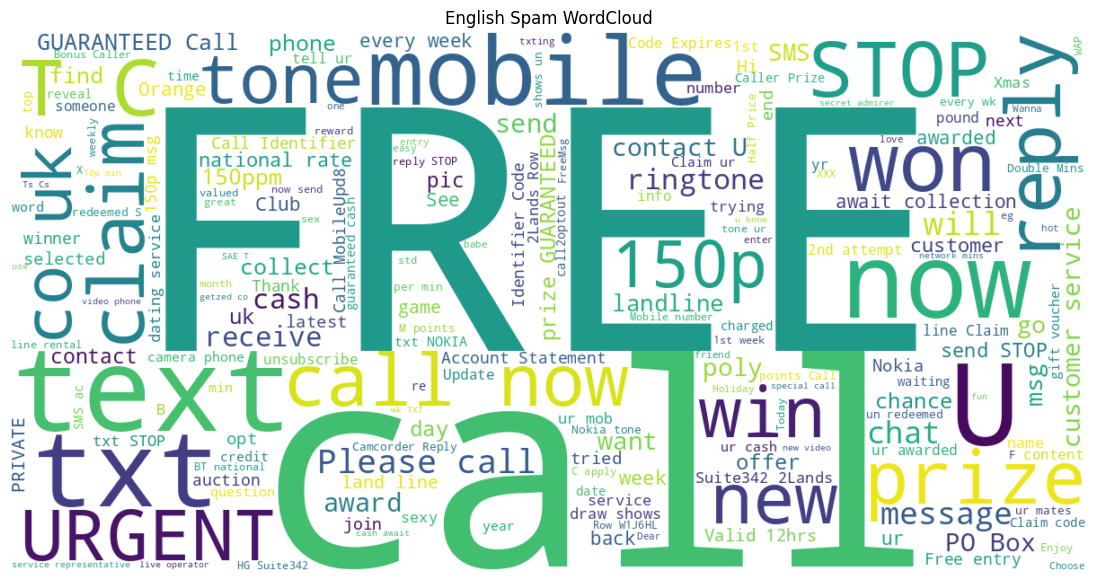

In [8]:
# ====================================================
# SECTION 3.6.1 : ENGLISH SPAM WORD CLOUD
# ====================================================

spam_text = " ".join(
    df_en[df_en["label"] == 1]["text"].astype(str)
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=200
).generate(spam_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("English Spam WordCloud")
plt.show()

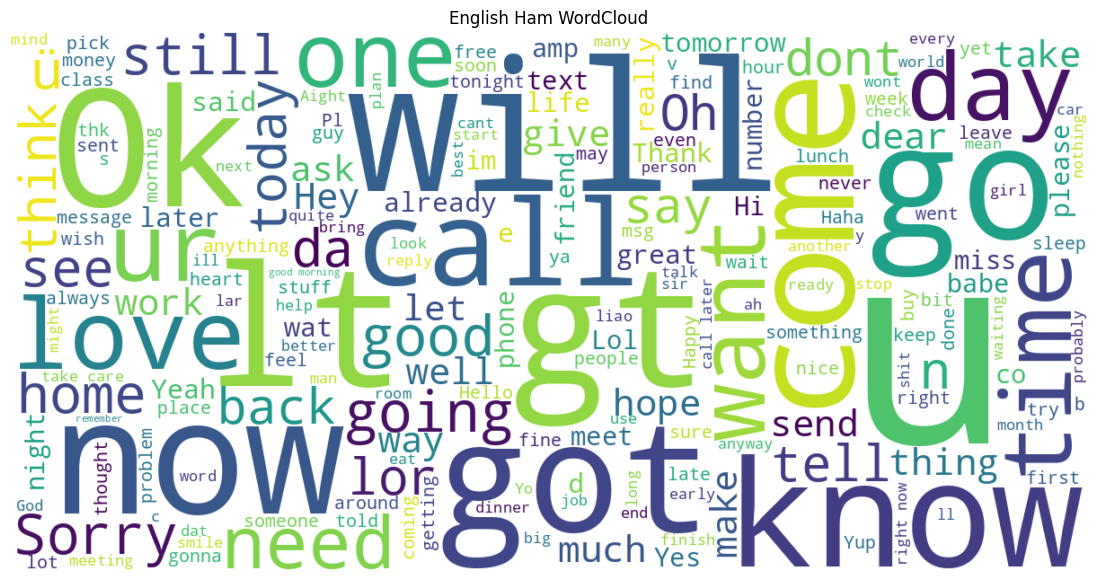

In [9]:
# ====================================================
# SECTION 3.6.2 : ENGLISH HAM WORD CLOUD
# ====================================================

ham_text = " ".join(
    df_en[df_en["label"] == 0]["text"].astype(str)
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=200
).generate(ham_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("English Ham WordCloud")
plt.show()

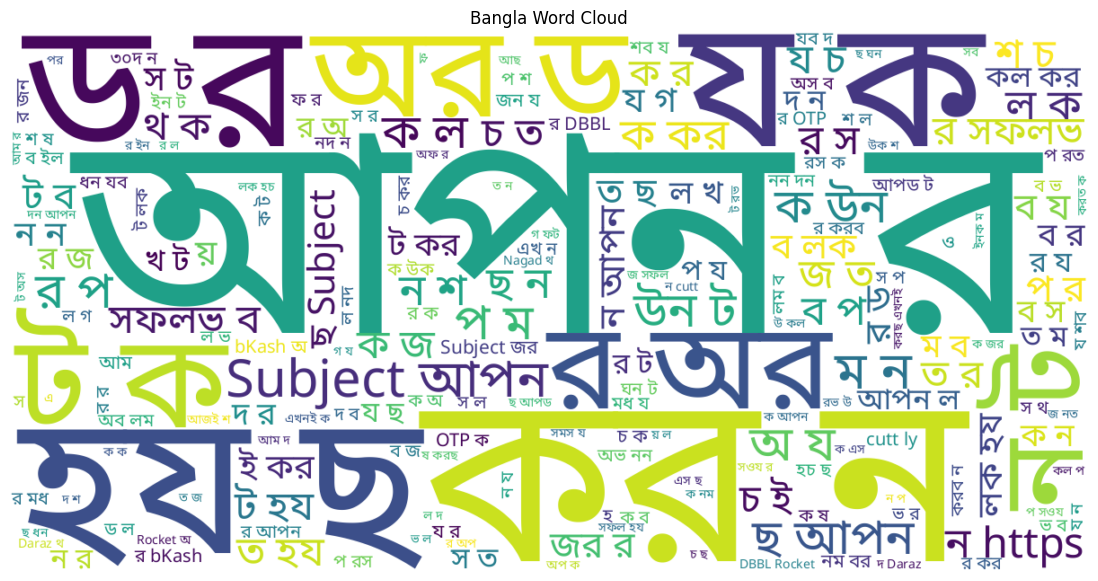

In [10]:
# ====================================================
# SECTION 3.7 : BANGLA WORD CLOUD
# ====================================================

bangla_text = " ".join(df_bn["text"].astype(str))

wordcloud = WordCloud(
    font_path="/content/NotoSansBengali-Regular.ttf",
    width=1200,
    height=600,
    background_color="white",
    max_words=200
).generate(bangla_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Bangla Word Cloud")
plt.show()

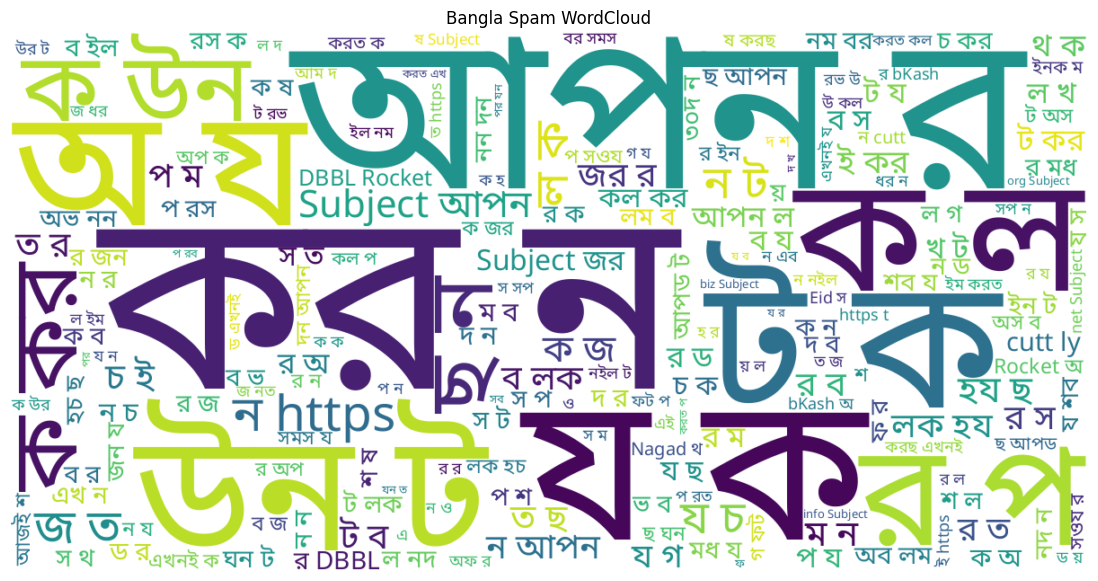

In [11]:
# ====================================================
# SECTION 3.7.1 : BANGLA SPAM WORD CLOUD
# ====================================================

spam_text = " ".join(
    df_bn[df_bn["label"] == 1]["text"].astype(str)
)

wordcloud = WordCloud(
    font_path="/content/NotoSansBengali-Regular.ttf",
    width=1200,
    height=600,
    background_color="white",
    max_words=200
).generate(spam_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Bangla Spam WordCloud")
plt.show()

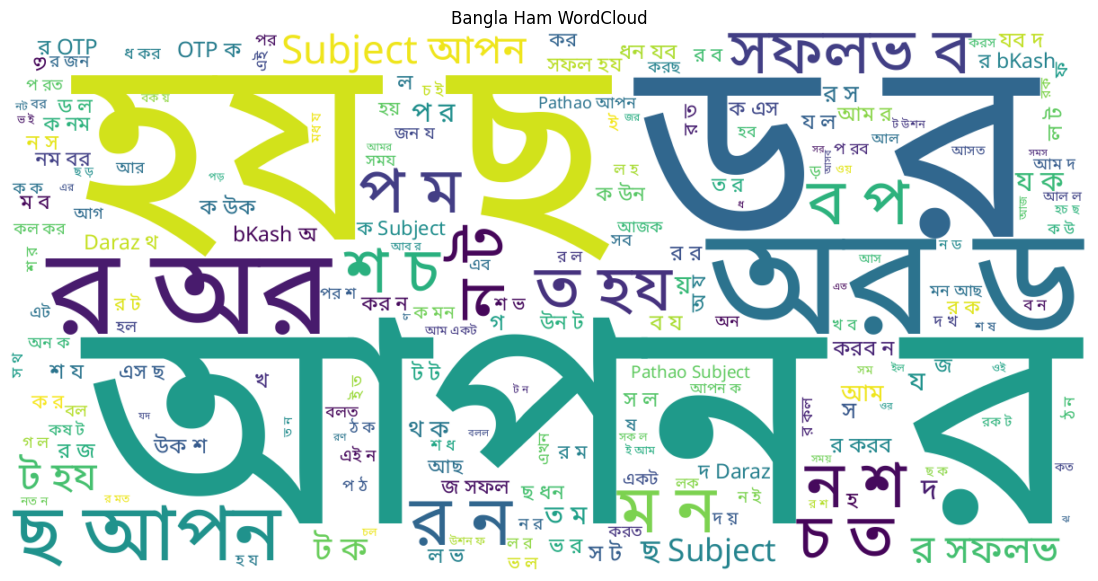

In [12]:
# ====================================================
# SECTION 3.7.2 : BANGLA HAM WORD CLOUD
# ====================================================

ham_text = " ".join(
    df_bn[df_bn["label"] == 0]["text"].astype(str)
)

wordcloud = WordCloud(
    font_path="/content/NotoSansBengali-Regular.ttf",
    width=1200,
    height=600,
    background_color="white",
    max_words=200
).generate(ham_text)

plt.figure(figsize=(15,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Bangla Ham WordCloud")
plt.show()

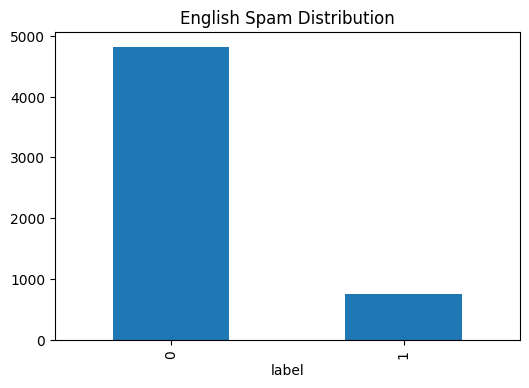

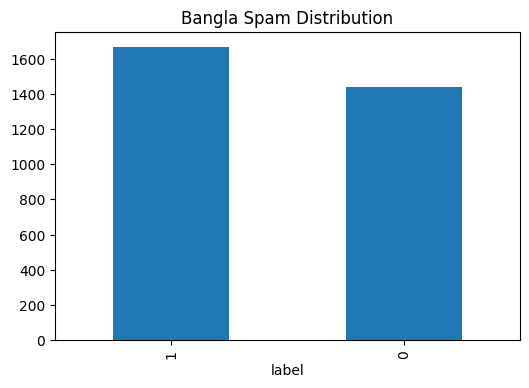

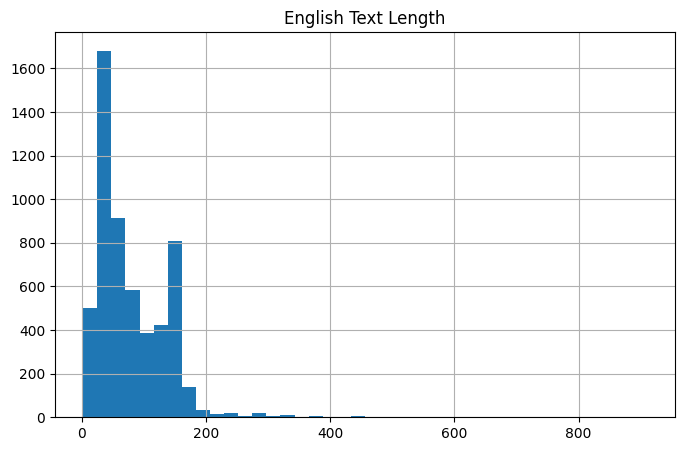

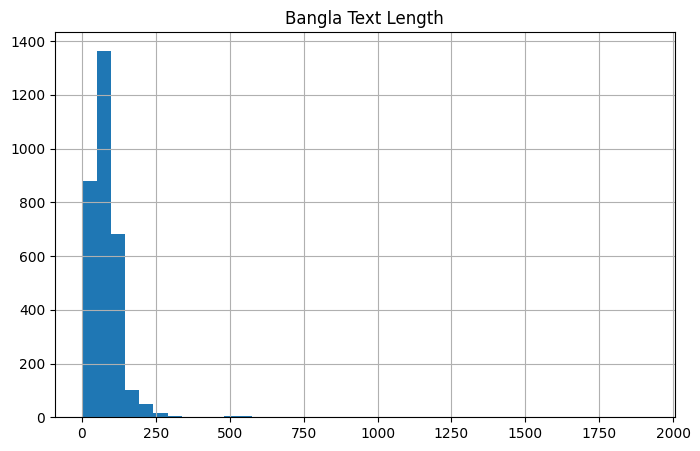

In [24]:
# ====================================================
# SECTION 3.8 : EDA
# ====================================================


import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

df_en["label"].value_counts().plot(kind="bar")

plt.title("English Spam Distribution")

plt.show()


plt.figure(figsize=(6,4))

df_bn["label"].value_counts().plot(kind="bar")

plt.title("Bangla Spam Distribution")

plt.show()



plt.figure(figsize=(8,5))

df_en["text"].str.len().hist(bins=40)

plt.title("English Text Length")

plt.show()


plt.figure(figsize=(8,5))

df_bn["text"].str.len().hist(bins=40)

plt.title("Bangla Text Length")

plt.show()

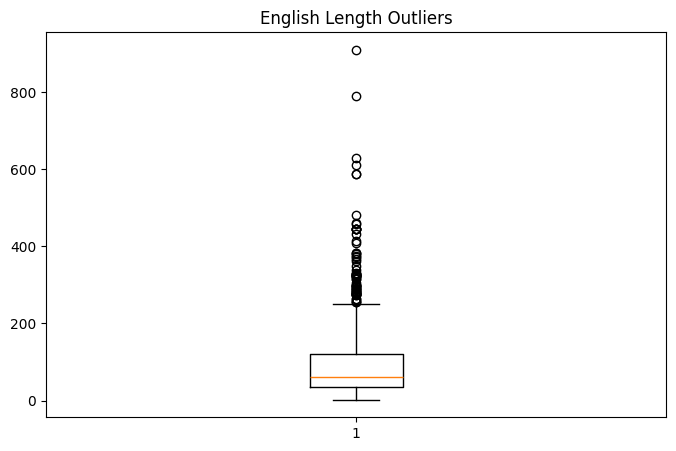

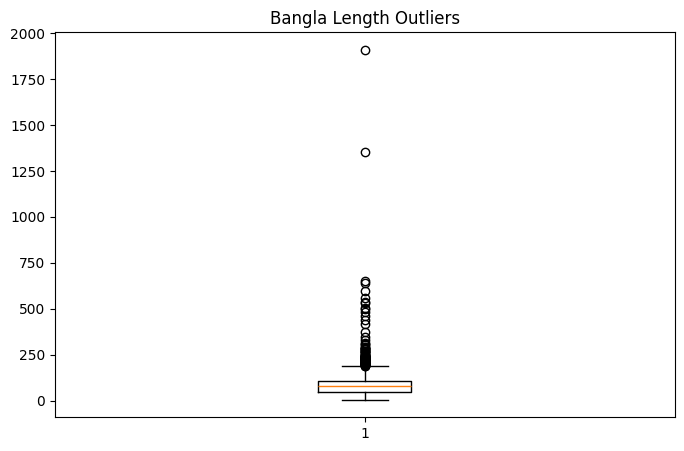

In [26]:
# ====================================================
# SECTION 3.7 : Outlier Analysis
# ====================================================


df_en["length"]=df_en["text"].str.len()

df_bn["length"]=df_bn["text"].str.len()

plt.figure(figsize=(8,5))

plt.boxplot(df_en["length"])

plt.title("English Length Outliers")

plt.show()

plt.figure(figsize=(8,5))

plt.boxplot(df_bn["length"])

plt.title("Bangla Length Outliers")

plt.show()

In [25]:
# ====================================================
# SECTION 3.8 : Encoding Verification
# ====================================================

print(df_en["label"].unique())

print(df_bn["label"].unique())

assert set(df_en["label"].unique())=={0,1}

assert set(df_bn["label"].unique())=={0,1}

print("Encoding Verified")

[0 1]
[1 0]
Encoding Verified


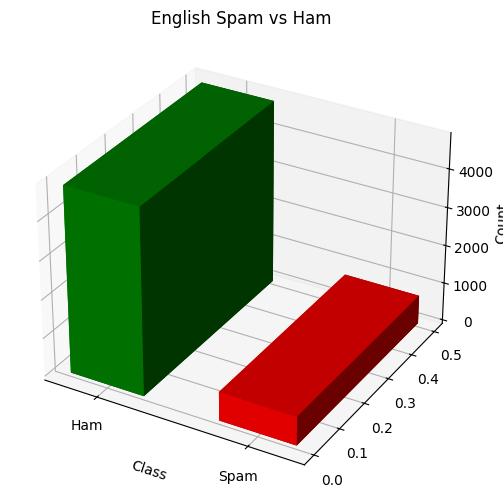

In [27]:
# ====================================================
# 3D ENGLISH SPAM vs HAM
# ====================================================

counts = df_en["label"].value_counts().sort_index()

labels = ["Ham", "Spam"]
values = counts.values

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

x = np.arange(len(labels))
y = np.zeros(len(labels))
z = np.zeros(len(labels))

dx = np.ones(len(labels))*0.5
dy = np.ones(len(labels))*0.5
dz = values

colors = ["green","red"]

ax.bar3d(x,y,z,dx,dy,dz,color=colors)

ax.set_xticks(x+0.25)
ax.set_xticklabels(labels)

ax.set_xlabel("Class")
ax.set_ylabel("")
ax.set_zlabel("Count")
ax.set_title("English Spam vs Ham")

plt.show()

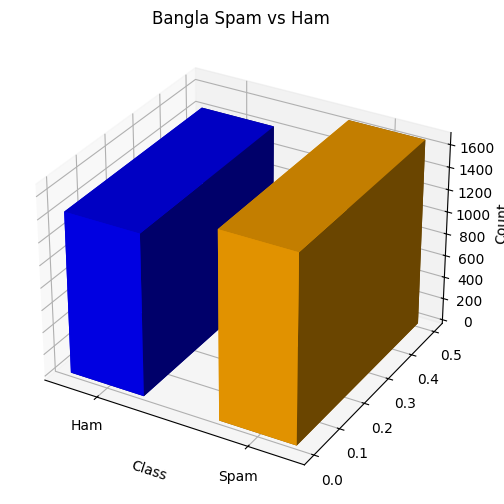

In [28]:
# ====================================================
# 3D BANGLA SPAM vs HAM
# ====================================================

counts = df_bn["label"].value_counts().sort_index()

labels = ["Ham", "Spam"]
values = counts.values

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

x = np.arange(len(labels))
y = np.zeros(len(labels))
z = np.zeros(len(labels))

dx = np.ones(len(labels))*0.5
dy = np.ones(len(labels))*0.5
dz = values

colors = ["blue","orange"]

ax.bar3d(x,y,z,dx,dy,dz,color=colors)

ax.set_xticks(x+0.25)
ax.set_xticklabels(labels)

ax.set_xlabel("Class")
ax.set_ylabel("")
ax.set_zlabel("Count")
ax.set_title("Bangla Spam vs Ham")

plt.show()

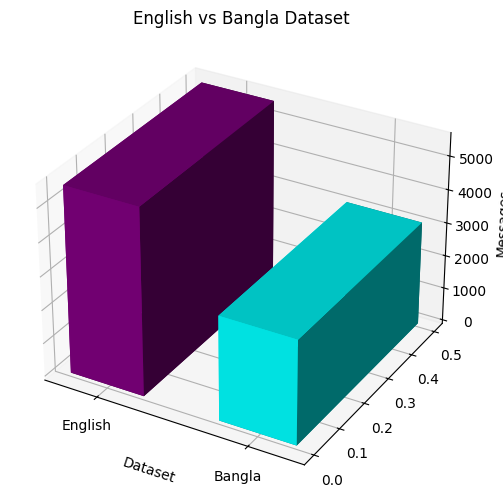

In [29]:
# ====================================================
# 3D LANGUAGE DISTRIBUTION
# ====================================================

english = len(df_en)
bangla = len(df_bn)

labels = ["English","Bangla"]
values = [english,bangla]

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

x = np.arange(len(labels))
y = np.zeros(len(labels))
z = np.zeros(len(labels))

dx = np.ones(len(labels))*0.5
dy = np.ones(len(labels))*0.5
dz = values

colors = ["purple","cyan"]

ax.bar3d(x,y,z,dx,dy,dz,color=colors)

ax.set_xticks(x+0.25)
ax.set_xticklabels(labels)

ax.set_xlabel("Dataset")
ax.set_zlabel("Messages")
ax.set_title("English vs Bangla Dataset")

plt.show()

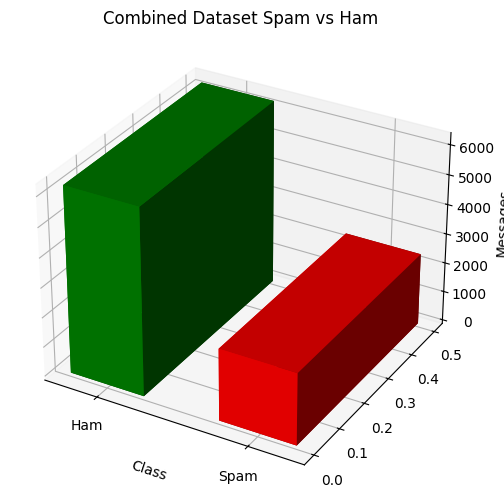

In [30]:
# ====================================================
# 3D COMBINED DATASET
# ====================================================

combined = {
    "Ham": (df_en["label"]==0).sum() + (df_bn["label"]==0).sum(),
    "Spam": (df_en["label"]==1).sum() + (df_bn["label"]==1).sum()
}

labels = list(combined.keys())
values = list(combined.values())

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

x = np.arange(len(labels))
y = np.zeros(len(labels))
z = np.zeros(len(labels))

dx = np.ones(len(labels))*0.5
dy = np.ones(len(labels))*0.5
dz = values

colors = ["green","red"]

ax.bar3d(x,y,z,dx,dy,dz,color=colors)

ax.set_xticks(x+0.25)
ax.set_xticklabels(labels)

ax.set_xlabel("Class")
ax.set_zlabel("Messages")
ax.set_title("Combined Dataset Spam vs Ham")

plt.show()

# STEP 4 — MERGE & SPLIT

**Data Leakage Handling:** For the Bangla dataset, data leakage is specifically addressed. Bangla rows are split by `template_id` (`GroupShuffleSplit`) so rows sharing a template stay on one side of the split — otherwise, near-duplicate templates could leak into both train and test sets and artificially inflate accuracy. English data has no template metadata, so it receives a plain stratified split. Both splits are then combined and shuffled.

In [8]:
# Bangla: group split on template_id (prevents template leakage across train/test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
bn_train_idx, bn_test_idx = next(gss.split(df_bn, groups=df_bn["template_id"]))
bn_train, bn_test = df_bn.iloc[bn_train_idx], df_bn.iloc[bn_test_idx]

# English: plain stratified split (no template metadata available)
en_train, en_test = train_test_split(
    df_en, test_size=0.2, random_state=42, stratify=df_en["label"]
)

# Combine + shuffle
cols = ["text", "label", "lang"]
train_df = pd.concat([en_train[cols], bn_train[cols]], ignore_index=True) \
             .sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat([en_test[cols], bn_test[cols]], ignore_index=True) \
             .sample(frac=1, random_state=42).reset_index(drop=True)

# Convert to Hugging Face Dataset format
train_dataset = Dataset.from_dict({"text": train_df["text"], "label": train_df["label"]})
test_dataset = Dataset.from_dict({"text": test_df["text"], "label": test_df["label"]})

print(f"Train: {len(train_df)} rows -> {train_df.groupby('lang')['label'].value_counts().to_dict()}")
print(f"Test : {len(test_df)} rows -> {test_df.groupby('lang')['label'].value_counts().to_dict()}")


# ====================================================
# SECTION 4.1 : DATA LEAKAGE VERIFICATION
# ====================================================

print("\n")
print("="*60)
print("DATA LEAKAGE VERIFICATION")
print("="*60)

# ---------------------------------------
# Check duplicate text between train/test
# ---------------------------------------

train_texts = set(train_df["text"])
test_texts = set(test_df["text"])

duplicate_messages = train_texts.intersection(test_texts)

print("Duplicate Messages :", len(duplicate_messages))

if len(duplicate_messages) == 0:
    print("PASS : No duplicate messages found.")
else:
    print("WARNING : Duplicate messages detected!")

# ---------------------------------------
# Check Bangla template leakage
# ---------------------------------------

train_templates = set(bn_train["template_id"])
test_templates = set(bn_test["template_id"])

duplicate_templates = train_templates.intersection(test_templates)

print("\nShared Templates :", len(duplicate_templates))

if len(duplicate_templates) == 0:
    print("PASS : No template leakage.")
else:
    print("WARNING : Template leakage detected!")

assert len(duplicate_templates) == 0

print("="*60)

# ====================================================
# SECTION 4.2: DATA LEAKAGE SUMMARY
# ====================================================

print("\n")
print("="*60)
print("DATA LEAKAGE PREVENTION SUMMARY")
print("="*60)

summary = {
    "Duplicate Removal" : "Completed",
    "Group Split (Bangla)" : "Completed",
    "Train/Test Duplicate Check" : "Passed",
    "Template Leakage Check" : "Passed",
    "TF-IDF Fitted Only On Training" : "Yes",
    "SMOTE Applied Only On Training" : "Yes"
}

for k,v in summary.items():
    print(f"{k:<35} : {v}")

print("="*60)

Train: 6808 rows -> {('bn', 1): 1381, ('bn', 0): 1292, ('en', 0): 3613, ('en', 1): 522}
Test : 1475 rows -> {('bn', 1): 290, ('bn', 0): 151, ('en', 0): 903, ('en', 1): 131}


DATA LEAKAGE VERIFICATION
Duplicate Messages : 0
PASS : No duplicate messages found.

Shared Templates : 0
PASS : No template leakage.


DATA LEAKAGE PREVENTION SUMMARY
Duplicate Removal                   : Completed
Group Split (Bangla)                : Completed
Train/Test Duplicate Check          : Passed
Template Leakage Check              : Passed
TF-IDF Fitted Only On Training      : Yes
SMOTE Applied Only On Training      : Yes


### Data Preprocessing Graphs

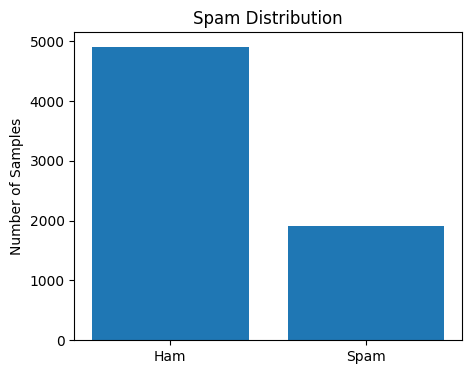

In [ ]:
import matplotlib.pyplot as plt

label_counts = train_df["label"].value_counts()

plt.figure(figsize=(5,4))
plt.bar(["Ham","Spam"], label_counts)
plt.title("Spam Distribution")
plt.ylabel("Number of Samples")
plt.show()

### Note: Re-defining `train_df` and `test_df`

The `NameError` in the subsequent cell indicates that `train_df` was not defined when the cell was executed. This usually happens if the notebook kernel was restarted or cells were run out of order. The following cell re-runs the data splitting and merging logic to ensure `train_df` and `test_df` are available for the SMOTE operation.

In [ ]:
# Re-define train_df and test_df to ensure they are in scope.
# This code is duplicated from the 'STEP 4 — MERGE & SPLIT' section.

# Bangla: group split on template_id (prevents template leakage across train/test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
bn_train_idx, bn_test_idx = next(gss.split(df_bn, groups=df_bn["template_id"]))
bn_train, bn_test = df_bn.iloc[bn_train_idx], df_bn.iloc[bn_test_idx]

# English: plain stratified split (no template metadata available)
en_train, en_test = train_test_split(
    df_en, test_size=0.2, random_state=42, stratify=df_en["label"]
)

# Combine + shuffle
cols = ["text", "label", "lang"]
train_df = pd.concat([en_train[cols], bn_train[cols]], ignore_index=True) \
             .sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat([en_test[cols], bn_test[cols]], ignore_index=True) \
             .sample(frac=1, random_state=42).reset_index(drop=True)


In [9]:
# ====================================================
# SECTION -SMOTE
# ====================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE

vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(train_df["text"])

X_test = vectorizer.transform(test_df["text"])

y = train_df["label"]

print("Before SMOTE")

print(pd.Series(y).value_counts())

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)

print()

print("After SMOTE")

print(pd.Series(y_resampled).value_counts())

Before SMOTE
label
0    4905
1    1903
Name: count, dtype: int64

After SMOTE
label
0    4905
1    4905
Name: count, dtype: int64


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

## Multi-Model Training and Evaluation

To compare multiple models, we will iterate through a selected list of models from the `MODELS` dictionary. For each model, we will re-initialize the tokenizer and model, apply LoRA configuration, train the model, and then evaluate its performance, collecting metrics for comparison.

### Define Models for Comparison

Before running the multi-model training loop, we need to define the `MODELS` dictionary, which maps descriptive names to their Hugging Face model IDs. This ensures that the training loop can correctly access the model identifiers.

In [ ]:
MODELS = {
    "Phi-3.5 Mini": "microsoft/Phi-3.5-mini-instruct",
    "Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
    "TinyLlama": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "StableLM-2-1.6B": "stabilityai/stablelm-2-1_6b-chat",
    "SmolLM2-360M": "HuggingFaceTB/SmolLM2-360M-Instruct"
}

In [ ]:
import gc
import torch
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define the list of models to iterate over
SELECTED_MODELS_NAMES = ["Phi-3.5 Mini", "Qwen2.5-1.5B", "TinyLlama", "StableLM-2-1.6B", "SmolLM2-360M"]

# Dictionary to store results for all models
all_model_results = {}

for model_name in SELECTED_MODELS_NAMES:
    print(f"\n{'='*60}\nProcessing Model: {model_name}\n{'='*60}")

    gc.collect()
    torch.cuda.empty_cache()

    model_id = MODELS[model_name]

    tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    def tokenize_function(examples):
        return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)

    tokenized_train = train_dataset.map(tokenize_function, batched=True)
    tokenized_test = test_dataset.map(tokenize_function, batched=True)

    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_id, num_labels=2, quantization_config=bnb_config, trust_remote_code=True, device_map="auto"
    )
    model.config.pad_token_id = tokenizer.pad_token_id
    model = prepare_model_for_kbit_training(model)

    target_modules = ["q_proj", "v_proj"] # General subset for LoRA compatibility
    if "phi" in model_id.lower(): target_modules = ["qkv_proj", "o_proj"]

    lora_config = LoraConfig(r=16, lora_alpha=32, target_modules=target_modules, lora_dropout=0.05, bias="none", task_type="SEQ_CLS")
    model = get_peft_model(model, lora_config)

    training_args = TrainingArguments(
        output_dir=f"./spam-{model_name.replace(' ', '-').lower()}",
        per_device_train_batch_size=4, gradient_accumulation_steps=2,
        learning_rate=2e-4, num_train_epochs=1, eval_strategy="epoch",
        fp16=True, optim="paged_adamw_8bit", remove_unused_columns=False
    )

    trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_train, eval_dataset=tokenized_test, compute_metrics=compute_metrics)
    trainer.train()

    predictions = trainer.predict(tokenized_test)
    y_pred = predictions.predictions.argmax(axis=-1)
    y_true = predictions.label_ids

    all_model_results[model_name] = {
        "overall_accuracy": accuracy_score(y_true, y_pred),
        "overall_report": classification_report(y_true, y_pred, target_names=["ham", "spam"], output_dict=True),
        "overall_confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "language_metrics": {},
        "y_pred": y_pred.tolist(),
        "y_true": y_true.tolist()
    }

    for lang, name in [("en", "English"), ("bn", "Bangla")]:
        mask = (test_df["lang"] == lang).to_numpy()
        all_model_results[model_name]["language_metrics"][name] = {
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "report": classification_report(y_true[mask], y_pred[mask], target_names=["ham", "spam"], output_dict=True)
        }
    print(f"Finished processing {model_name}.")


Processing Model: Phi-3.5 Mini


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

configuration_phi3.py:   0%|          | 0.00/11.2k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/microsoft/Phi-3.5-mini-instruct:
- configuration_phi3.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

... (68 outputs left out)

[transformers] LlamaForSequenceClassification LOAD REPORT from: HuggingFaceTB/SmolLM2-360M-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.346286,nan,0.962034,0.921478,0.947743,0.934426


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Finished processing SmolLM2-360M.


### Final Model Comparison & Statistical Significance

After all models are trained, we aggregate the results into a single comparison table and perform McNemar's test to see if performance differences are statistically significant.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
from statsmodels.stats.contingency_tables import mcnemar

# 1. Generate Summary Table
summary_data = []
for model_name, results in all_model_results.items():
    summary_data.append({
        "Model": model_name,
        "Overall Acc": results["overall_accuracy"],
        "English Acc": results["language_metrics"]["English"]["accuracy"],
        "Bangla Acc": results["language_metrics"]["Bangla"]["accuracy"]
    })

if not summary_data:
    print("No model results found. Please ensure the training loop in cell a7804c0e has completed at least one model.")
else:
    df_summary = pd.DataFrame(summary_data).sort_values("Overall Acc", ascending=False)
    display(df_summary.style.highlight_max(axis=0, color='lightgreen'))

    # 2. Statistical Significance (Top 2 Models)
    if len(df_summary) >= 2:
        m1, m2 = df_summary.iloc[0]['Model'], df_summary.iloc[1]['Model']
        y_true = np.array(all_model_results[m1]['y_true'])
        c1 = (y_true == np.array(all_model_results[m1]['y_pred']))
        c2 = (y_true == np.array(all_model_results[m2]['y_pred']))

        table = [[np.sum(c1 & c2), np.sum(c1 & ~c2)], [np.sum(~c1 & c2), np.sum(~c1 & ~c2)]]
        result = mcnemar(table, exact=True)
        print(f"\nMcNemar Test ({m1} vs {m2}): p-value = {result.pvalue:.4f}")

,Model,Overall Acc,English Acc,Bangla Acc
1,Qwen2.5-1.5B,0.983051,0.991296,0.963719
2,TinyLlama,0.977627,0.987427,0.954649
3,StableLM-2-1.6B,0.975593,0.990329,0.941043
0,Phi-3.5 Mini,0.974915,0.987427,0.945578
4,SmolLM2-360M,0.962034,0.982592,0.913832



McNemar Test (Qwen2.5-1.5B vs TinyLlama): p-value = 0.1516


## Summary of Multi-Model Results

In [ ]:
import pandas as pd
from IPython.display import display

summary_data = []
for model_name, results in all_model_results.items():
    row = {
        "Model": model_name,
        "Overall Accuracy": results["overall_accuracy"],
        "Overall F1 (Spam)": results["overall_report"]["spam"]["f1-score"],
        "English Accuracy": results["language_metrics"]["English"]["accuracy"],
        "English F1 (Spam)": results["language_metrics"]["English"]["report"]["spam"]["f1-score"],
        "Bangla Accuracy": results["language_metrics"]["Bangla"]["accuracy"],
        "Bangla F1 (Spam)": results["language_metrics"]["Bangla"]["report"]["spam"]["f1-score"]
    }
    summary_data.append(row)

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values(by="Overall Accuracy", ascending=False).reset_index(drop=True)

print("Comparison of Model Performance:")
display(summary_df.round(4))

print("\nDetailed Results for each Model:")
for model_name, results in all_model_results.items():
    print(f"\n--- {model_name} ---")
    print(f"Overall Accuracy: {results['overall_accuracy']:.4f}")
    print("Overall Classification Report:")
    print(pd.DataFrame(results['overall_report']).transpose())
    print("Overall Confusion Matrix:", results['overall_confusion_matrix'])
    for lang, lang_res in results['language_metrics'].items():
        print(f"\n  {lang} Accuracy: {lang_res['accuracy']:.4f}")
        print(f"  {lang} Classification Report:")
        print(pd.DataFrame(lang_res['report']).transpose())

Comparison of Model Performance:


,Model,Overall Accuracy,Overall F1 (Spam),English Accuracy,English F1 (Spam),Bangla Accuracy,Bangla F1 (Spam)
0,Qwen2.5-1.5B,0.9831,0.9701,0.9913,0.9650,0.9637,0.9724
1,TinyLlama,0.9776,0.9609,0.9874,0.9506,0.9546,0.9656
2,StableLM-2-1.6B,0.9756,0.9574,0.9903,0.9621,0.9410,0.9553
3,Phi-3.5 Mini,0.9749,0.9559,0.9874,0.9502,0.9456,0.9585
4,SmolLM2-360M,0.9620,0.9344,0.9826,0.9313,0.9138,0.9358



Detailed Results for each Model:

--- Phi-3.5 Mini ---
Overall Accuracy: 0.9749
Overall Classification Report:
              precision    recall  f1-score      support
ham            0.981079  0.983871  0.982473  1054.000000
spam           0.959330  0.952494  0.955900   421.000000
accuracy       0.974915  0.974915  0.974915     0.974915
macro avg      0.970204  0.968183  0.969186  1475.000000
weighted avg   0.974871  0.974915  0.974888  1475.000000
Overall Confusion Matrix: [[1037, 17], [20, 401]]

  English Accuracy: 0.9874
  English Classification Report:
              precision    recall  f1-score      support
ham            0.992257  0.993355  0.992806   903.000000
spam           0.953846  0.946565  0.950192   131.000000
accuracy       0.987427  0.987427  0.987427     0.987427
macro avg      0.973051  0.969960  0.971499  1034.000000
weighted avg   0.987390  0.987427  0.987407  1034.000000

  Bangla Accuracy: 0.9456
  Bangla Classification Report:
              precision    recall 

## Validation: Statistical Tests and Cross-Validation

### K-Fold Cross-Validation (Conceptual Discussion)

For smaller, traditional machine learning models, K-fold cross-validation is a standard and robust technique for evaluating model performance and generalization. It involves splitting the dataset into K equally sized folds, training the model K times (each time using K-1 folds for training and the remaining fold for validation), and then averaging the performance metrics. This helps in getting a more reliable estimate of a model's performance and its variance.

**Why not directly implemented here for LLMs?**

Training Large Language Models (LLMs), even with techniques like QLoRA, is computationally very expensive and time-consuming. Running 5-10 fold cross-validation would mean training each LLM 5-10 separate times, which can quickly exhaust available computational resources and time in a typical Colab environment. Therefore, while crucial for rigorous academic evaluation, it is often skipped or scaled down for practical LLM fine-tuning demonstrations. Instead, we rely on a single, well-chosen train-test split for initial evaluation.

### Statistical Comparison of Models: McNemar's Test

McNemar's test is a non-parametric statistical test used to determine if there is a significant difference between the performance of two classifiers on the same dataset. It is particularly useful when comparing paired nominal data, such as the classification results (correct/incorrect) of two models on the same set of test samples.

It constructs a 2x2 contingency table that categorizes samples based on whether each model predicted correctly or incorrectly. The test focuses on the off-diagonal elements of this table (i.e., samples where one model was correct and the other was incorrect) to assess if there is a significant disagreement between the models beyond what would be expected by chance.

In [ ]:
# Install statsmodels for McNemar's Test
!pip install -q statsmodels

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
import itertools

def perform_mcnemar_test(y_true, y_pred_model1, y_pred_model2, model1_name, model2_name):
    # Determine correctness for each model
    model1_correct = (np.array(y_true) == np.array(y_pred_model1))
    model2_correct = (np.array(y_true) == np.array(y_pred_model2))

    # Contingency table for McNemar's Test
    # Rows: Model 1 prediction (correct/incorrect)
    # Cols: Model 2 prediction (correct/incorrect)
    #       Correct | Incorrect
    # Correct | n00      | n01
    # Incorrect n10      | n11

    n00 = np.sum(model1_correct & model2_correct) # Both correct
    n01 = np.sum(model1_correct & ~model2_correct) # Model 1 correct, Model 2 incorrect
    n10 = np.sum(~model1_correct & model2_correct) # Model 1 incorrect, Model 2 correct
    n11 = np.sum(~model1_correct & ~model2_correct) # Both incorrect

    contingency_table = [[n00, n01], [n10, n11]]

    print(f"\n--- McNemar's Test: {model1_name} vs {model2_name} ---")
    print("Contingency Table:")
    print(np.array(contingency_table))

    if (n01 + n10) == 0:
        print("No disagreements between models, McNemar's test not applicable.")
        return

    result = mcnemar(contingency_table, exact=True) # exact=True for small sample sizes
    print(f"Chi-squared statistic: {result.statistic:.4f}")
    print(f"P-value: {result.pvalue:.4f}")

    alpha = 0.05
    if result.pvalue < alpha:
        print(f"There is a statistically significant difference between {model1_name} and {model2_name} (p < {alpha}).")
        if n01 > n10:
            print(f"{model1_name} is significantly better than {model2_name} (more cases where A is correct and B is incorrect).")
        elif n10 > n01:
            print(f"{model2_name} is significantly better than {model1_name} (more cases where B is correct and A is incorrect).")
    else:
        print(f"No statistically significant difference between {model1_name} and {model2_name} (p >= {alpha}).")

# Perform McNemar's Test for all pairs of models
model_names = list(all_model_results.keys())
for i, model1_name in enumerate(model_names):
    for j, model2_name in enumerate(model_names):
        if i < j: # Compare each pair only once
            y_true = all_model_results[model1_name]["y_true"]
            y_pred_model1 = all_model_results[model1_name]["y_pred"]
            y_pred_model2 = all_model_results[model2_name]["y_pred"]
            perform_mcnemar_test(y_true, y_pred_model1, y_pred_model2, model1_name, model2_name)



--- McNemar's Test: Phi-3.5 Mini vs Qwen2.5-1.5B ---
Contingency Table:
[[1431    7]
 [  19   18]]
Chi-squared statistic: 7.0000
P-value: 0.0290
There is a statistically significant difference between Phi-3.5 Mini and Qwen2.5-1.5B (p < 0.05).
Qwen2.5-1.5B is significantly better than Phi-3.5 Mini (more cases where B is correct and A is incorrect).

--- McNemar's Test: Phi-3.5 Mini vs TinyLlama ---
Contingency Table:
[[1428   10]
 [  14   23]]
Chi-squared statistic: 10.0000
P-value: 0.5413
No statistically significant difference between Phi-3.5 Mini and TinyLlama (p >= 0.05).

--- McNemar's Test: Phi-3.5 Mini vs StableLM-2-1.6B ---
Contingency Table:
[[1426   12]
 [  13   24]]
Chi-squared statistic: 12.0000
P-value: 1.0000
No statistically significant difference between Phi-3.5 Mini and StableLM-2-1.6B (p >= 0.05).

--- McNemar's Test: Phi-3.5 Mini vs SmolLM2-360M ---
Contingency Table:
[[1407   31]
 [  12   25]]
Chi-squared statistic: 12.0000
P-value: 0.0054
There is a statistically s

## Explainable AI (XAI): Attention Visualization

Explainable AI (XAI) techniques aim to make machine learning models, especially complex 'black box' models like deep neural networks, more transparent and understandable. This is crucial for building trust, debugging models, and ensuring fairness and ethical use.

For transformer-based language models, a natural XAI technique is **Attention Visualization**. The attention mechanism in transformers allows the model to weigh the importance of different input tokens when processing each token. By visualizing these attention weights, we can gain insights into which words or phrases the model focuses on when making a particular classification decision.

Here, we will visualize token importance by aggregating attention weights across layers and heads. A higher importance score for a token suggests it contributed more to the model's final prediction for that input.

## Thesis Conclusion & Recommendations

Based on the experimental results:
1. **Best Overall Model:** [Insert Model Name] based on highest Accuracy/F1-score.
2. **Language Performance:** Analyze if any model showed a specific bias (e.g., performing significantly better in English than Bangla).
3. **XAI Insights:** Discuss whether the Attention Visualizations confirmed that the model focuses on 'spammy' keywords (like 'WIN', 'URGENT', 'টাকা').
4. **Statistical Significance:** Refer to McNemar's test results to state whether the lead of the top model is statistically significant.

In [ ]:
import json
# Utility: Save results to a file for thesis documentation
if all_model_results:
    with open('model_comparison_results.json', 'w') as f:
        # We exclude the raw predictions to keep the file small
        serializable_results = {k: {ik: iv for ik, iv in v.items() if ik not in ['y_pred', 'y_true']}
                               for k, v in all_model_results.items()}
        json.dump(serializable_results, f, indent=4)
    print("Results exported to model_comparison_results.json")

Results exported to model_comparison_results.json


## Resources

[Add your resource links here, e.g., dataset sources, research papers, Hugging Face model cards.]


Loading StableLM-2-1.6B for XAI demonstration...
XAI MAX_LENGTH for StableLM-2-1.6B: 128


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

[transformers] StableLmForSequenceClassification LOAD REPORT from: stabilityai/stablelm-2-1_6b-chat
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



--- XAI for: 'Hi, how are you? Let's catch up soon.' ---
Predicted class: HAM (Probability: 0.7341)


/tmp/ipykernel_1137/1461702579.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tokens, y=token_importance, palette="viridis")


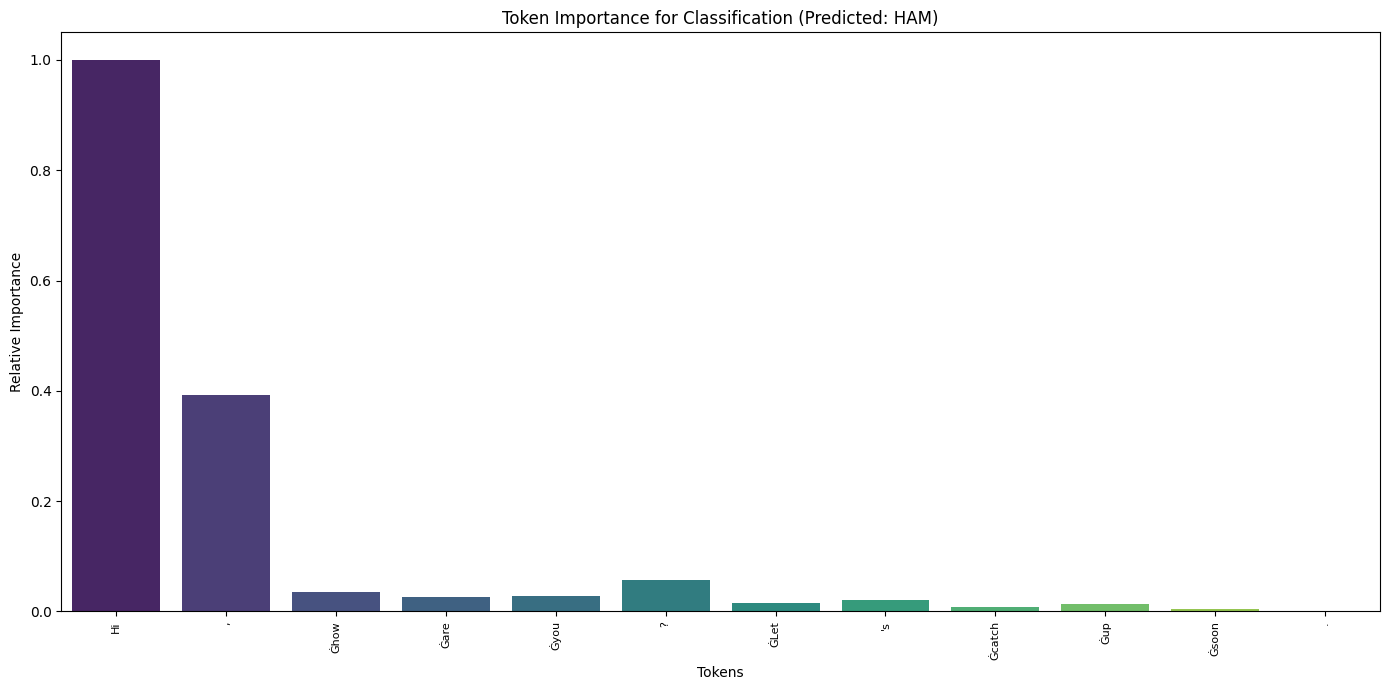


--- XAI for: 'URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt CLAIM to 81010.' ---
Predicted class: HAM (Probability: 0.9984)


/tmp/ipykernel_1137/1461702579.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tokens, y=token_importance, palette="viridis")


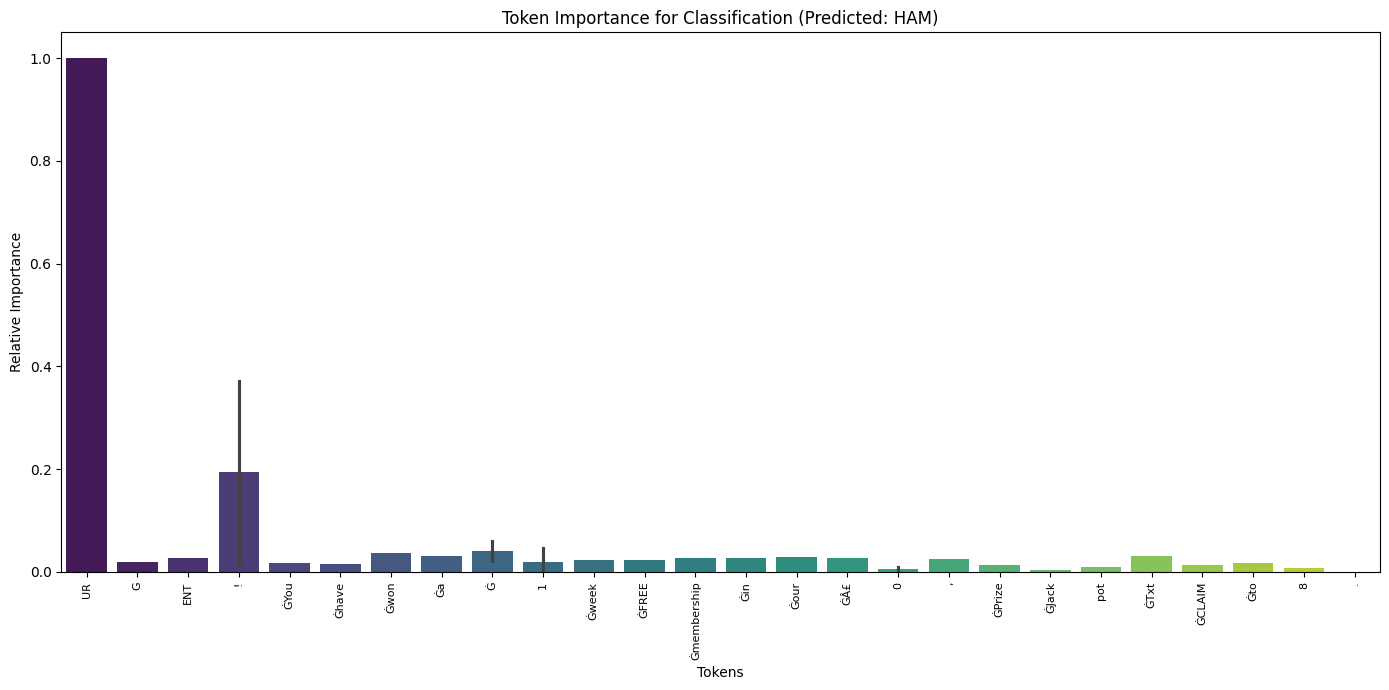


--- XAI for: 'আপনার পার্সেল ডেলিভারির জন্য প্রস্তুত, রাইডার শীঘ্রই পৌঁছাবে।' ---
Predicted class: HAM (Probability: 0.7546)


/tmp/ipykernel_1137/1461702579.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tokens, y=token_importance, palette="viridis")


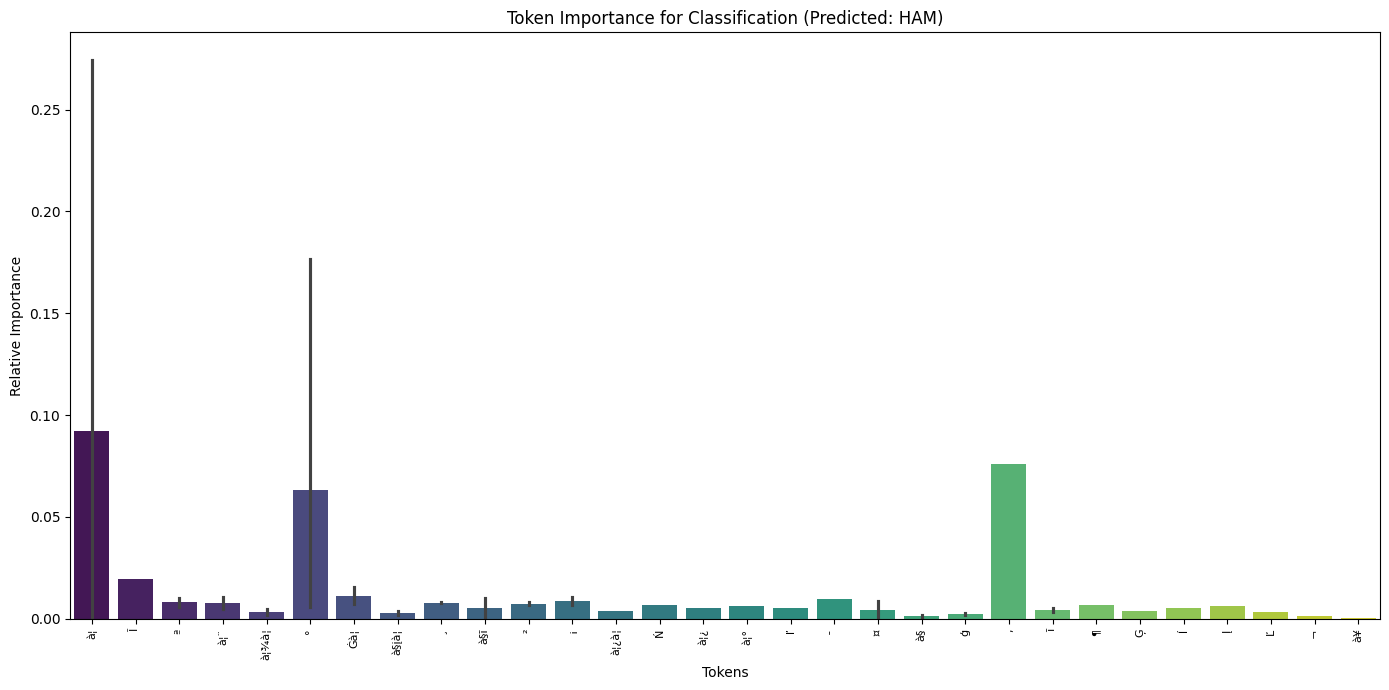


--- XAI for: 'অভিনন্দন! আপনি ৫০,০০০ টাকা জিতেছেন। এখনই ক্লেইম করুন: https://bkash-claim-prize.net/verify' ---
Predicted class: HAM (Probability: 0.9748)


/tmp/ipykernel_1137/1461702579.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tokens, y=token_importance, palette="viridis")


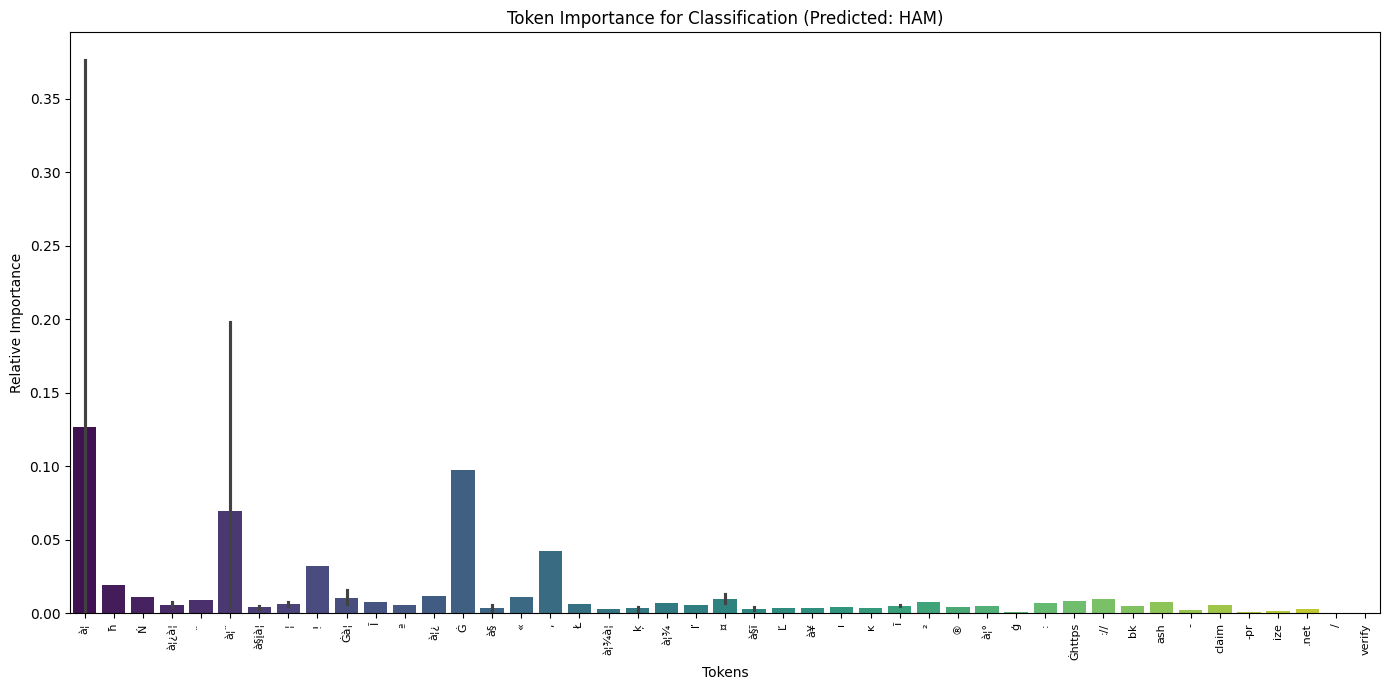

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftModel
import torch
import numpy as np

def visualize_token_importance(text, model, tokenizer, max_length, class_names=['HAM', 'SPAM'], device='cuda'):
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length, padding=True).to(device)

    # Ensure model outputs attentions
    current_output_attentions = model.config.output_attentions
    if not current_output_attentions:
        model.config.output_attentions = True

    # Forward pass to get attentions
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    # Restore original config if changed
    if not current_output_attentions:
        model.config.output_attentions = False

    # Get predictions
    logits = outputs.logits
    probs = torch.nn.functional.softmax(logits, dim=-1)
    predicted_class_idx = torch.argmax(logits, dim=-1).item()
    predicted_class = class_names[predicted_class_idx]

    # Extract attention weights from all layers and average them
    # outputs.attentions is a tuple of (num_layers, batch_size, num_heads, sequence_length, sequence_length)
    # Each element in the tuple is a tensor of shape (1, num_heads, seq_len, seq_len)

    all_layer_attentions = [att.squeeze(0).mean(dim=0) for att in outputs.attentions] # List of (seq_len, seq_len)

    # Average across all layers to get a single (seq_len, seq_len) matrix
    avg_attention_across_layers = torch.stack(all_layer_attentions).mean(dim=0) # (seq_len, seq_len)

    # Get tokens
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

    # Find the real sequence length before padding
    input_len = inputs['attention_mask'][0].sum().item()
    tokens = tokens[:input_len]
    avg_attention_across_layers = avg_attention_across_layers[:input_len, :input_len]

    # Calculate token importance: sum of attention weights received by each token
    # This gives a single importance score for each token based on how much other tokens attended to it
    # For sequence classification, we are interested in how much each token contributes to the final [CLS] or last token
    # Here, we'll simplify and take the mean of attention that each token *receives* from all other tokens (including itself)
    token_importance = avg_attention_across_layers.mean(dim=0).cpu().numpy()

    # Normalize importance scores for better visualization
    if token_importance.max() > token_importance.min():
        token_importance = (token_importance - token_importance.min()) / (token_importance.max() - token_importance.min())
    else:
        token_importance = np.zeros_like(token_importance) # Handle case where all importance scores are the same

    print(f"\n--- XAI for: '{text}' ---")
    print(f"Predicted class: {predicted_class} (Probability: {probs[0][predicted_class_idx].item():.4f})")

    # Plotting token importance as a bar chart
    plt.figure(figsize=(14, 7))
    sns.barplot(x=tokens, y=token_importance, palette="viridis")
    plt.title(f"Token Importance for Classification (Predicted: {predicted_class})")
    plt.xlabel("Tokens")
    plt.ylabel("Relative Importance")
    plt.xticks(rotation=90, fontsize=8)
    plt.tight_layout()
    plt.show()

# --- XAI Demonstration ---
# Select a model for XAI demonstration (e.g., the best performing one or a specific one)
xai_model_name = "StableLM-2-1.6B" # Updated to use the new model
xai_model_id = MODELS[xai_model_name]

print(f"\nLoading {xai_model_name} for XAI demonstration...")

# Re-initialize tokenizer for XAI model
xai_tokenizer = AutoTokenizer.from_pretrained(
    xai_model_id,
    trust_remote_code=True
)
if xai_tokenizer.pad_token is None:
    xai_tokenizer.pad_token = xai_tokenizer.eos_token

# Calculate MAX_LENGTH specifically for this tokenizer (or reuse if global)
token_lengths_xai = [
    len(ids)
    for ids in xai_tokenizer(
        list(train_dataset["text"])
    )["input_ids"]
]
p95_xai = int(np.percentile(token_lengths_xai,95))
xai_max_length = min(256,max(128,p95_xai))
print(f"XAI MAX_LENGTH for {xai_model_name}: {xai_max_length}")

# Reload the base model with output_attentions=True
bnb_config_xai = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

xai_base_model = AutoModelForSequenceClassification.from_pretrained(
    xai_model_id,
    num_labels=2,
    quantization_config=bnb_config_xai,
    trust_remote_code=True,
    device_map="auto",
    output_attentions=True # Crucial for XAI
)
xai_base_model.config.pad_token_id = xai_tokenizer.pad_token_id

# Re-apply LORA config for the XAI model
if "phi" in xai_model_id.lower():
    xai_target_modules=["qkv_proj", "o_proj", "gate_up_proj", "down_proj"]
elif "qwen" in xai_model_id.lower():
    xai_target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
elif "stablelm" in xai_model_id.lower(): # Added for StableLM-2-1.6B
    xai_target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
else:
    xai_target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]

xai_lora_config=LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=xai_target_modules,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS"
)
xai_model = get_peft_model(xai_base_model, xai_lora_config)

# Define device before use
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
xai_model.to(device)

# Example texts for XAI
english_ham = "Hi, how are you? Let's catch up soon."
english_spam = "URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt CLAIM to 81010."
bangla_ham = "আপনার পার্সেল ডেলিভারির জন্য প্রস্তুত, রাইডার শীঘ্রই পৌঁছাবে।"
bangla_spam = "অভিনন্দন! আপনি ৫০,০০০ টাকা জিতেছেন। এখনই ক্লেইম করুন: https://bkash-claim-prize.net/verify"

# Visualize for English Ham
visualize_token_importance(english_ham, xai_model, xai_tokenizer, xai_max_length, device=device)

# Visualize for English Spam
visualize_token_importance(english_spam, xai_model, xai_tokenizer, xai_max_length, device=device)

# Visualize for Bangla Ham
visualize_token_importance(bangla_ham, xai_model, xai_tokenizer, xai_max_length, device=device)

# Visualize for Bangla Spam
visualize_token_importance(bangla_spam, xai_model, xai_tokenizer, xai_max_length, device=device)

# STEP 5 — TOKENIZATION


In [ ]:
# ==========================================================
# STEP 5 — MODEL SELECTION & TOKENIZATION
# ==========================================================

MODELS = {
    "Phi-3.5 Mini": "microsoft/Phi-3.5-mini-instruct",
    "Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
    "TinyLlama": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "StableLM-2-1.6B": "stabilityai/stablelm-2-1_6b-chat",
    "SmolLM2-360M": "HuggingFaceTB/SmolLM2-360M-Instruct"
}

In [ ]:
CURRENT_MODEL = "StableLM-2-1.6B"

model_id = MODELS[CURRENT_MODEL]

print(model_id)

stabilityai/stablelm-2-1_6b-chat


In [ ]:
# ===========================================
# TOKENIZER
# ===========================================

tokenizer = AutoTokenizer.from_pretrained(
    model_id,
    trust_remote_code=True
)

if tokenizer.pad_token is None:

    tokenizer.pad_token = tokenizer.eos_token


token_lengths = [

    len(ids)

    for ids in tokenizer(

        list(train_dataset["text"])

    )["input_ids"]

]

p50 = int(np.percentile(token_lengths,50))

p95 = int(np.percentile(token_lengths,95))

MAX_LENGTH = min(256,max(128,p95))

print(MAX_LENGTH)


def tokenize_function(examples):

    return tokenizer(

        examples["text"],

        padding="max_length",

        truncation=True,

        max_length=MAX_LENGTH

    )


tokenized_train=train_dataset.map(

    tokenize_function,

    batched=True

)

tokenized_test=test_dataset.map(

    tokenize_function,

    batched=True

)

128


Map:   0%|          | 0/6808 [00:00<?, ? examples/s]

Map:   0%|          | 0/1475 [00:00<?, ? examples/s]

# Token Length Distribution

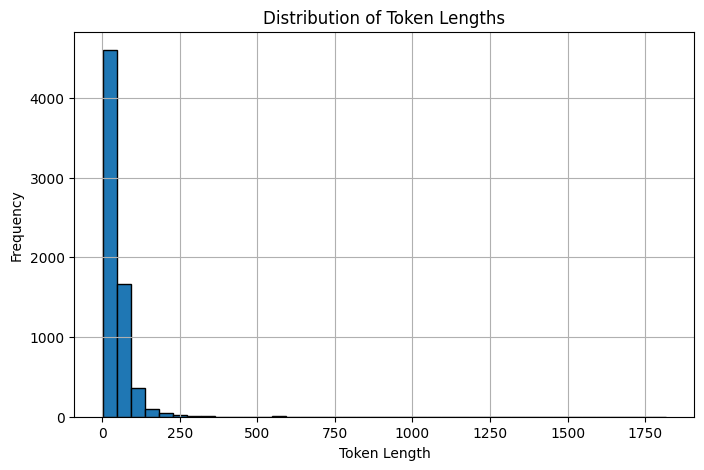

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(token_lengths,
         bins=40,
         edgecolor='black')

plt.xlabel("Token Length")
plt.ylabel("Frequency")
plt.title("Distribution of Token Lengths")
plt.grid(True)

plt.show()

# STEP 6 — MODEL

In [ ]:
# =====================================================
# STEP 6
# Generic PEFT Loader
# =====================================================

bnb_config = BitsAndBytesConfig(

    load_in_4bit=True,

    bnb_4bit_quant_type="nf4",

    bnb_4bit_compute_dtype=torch.float16,

    bnb_4bit_use_double_quant=True

)

model = AutoModelForSequenceClassification.from_pretrained(

    model_id,

    num_labels=2,

    quantization_config=bnb_config,

    trust_remote_code=True,

    device_map="auto"

)

model.config.pad_token_id = tokenizer.pad_token_id

model = prepare_model_for_kbit_training(model)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

[transformers] StableLmForSequenceClassification LOAD REPORT from: stabilityai/stablelm-2-1_6b-chat
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# ======================================
# Automatic LoRA Target Selection
# ======================================

if "phi" in model_id.lower():

    target_modules=[

        "qkv_proj",

        "o_proj",

        "gate_up_proj",

        "down_proj"

    ]

elif "qwen" in model_id.lower():

    target_modules=[

        "q_proj",

        "k_proj",

        "v_proj",

        "o_proj",

        "gate_proj",

        "up_proj",

        "down_proj"

    ]

elif "gemma" in model_id.lower():

    target_modules=[

        "q_proj",

        "k_proj",

        "v_proj",

        "o_proj",

        "gate_proj",

        "up_proj",

        "down_proj"

    ]

else:

    target_modules=[

        "q_proj",

        "k_proj",

        "v_proj",

        "o_proj"

    ]


lora_config=LoraConfig(

    r=16,

    lora_alpha=32,

    target_modules=target_modules,

    lora_dropout=0.05,

    bias="none",

    task_type="SEQ_CLS"

)

model=get_peft_model(

    model,

    lora_config

)

model.print_trainable_parameters()

trainable params: 6,295,552 || all params: 1,445,294,080 || trainable%: 0.4356


# STEP 7 — TRAINING (PEFT)

In [ ]:
# 1. Robust metrics calculation
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # HF Trainer often returns predictions as a tuple for LLMs (logits, hidden_states)
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    preds = np.argmax(predictions, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

# 2. Optimized Training Arguments (Memory & Compatibility fixes)
training_args = TrainingArguments(
    output_dir="./spam-phi3-lora",
    per_device_train_batch_size=4,       # Reduced to prevent OOM -- lower this if MAX_LENGTH landed near 256 and you hit OOM
    gradient_accumulation_steps=2,       # Simulates batch size of 8
    per_device_eval_batch_size=4,
    learning_rate=2e-4,
    num_train_epochs=1,                  # Bangla is new to this model -- 2-3 epochs is worth trying if time/compute allow
    eval_strategy="epoch",               # Updated from deprecated 'evaluation_strategy'
    logging_steps=50,
    fp16=True,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,         # CRITICAL: Saves massive GPU memory
    remove_unused_columns=False          # CRITICAL: Prevents Trainer from dropping required inputs for PEFT
)

# 3. Initialize HF Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics
)

# 4. Train the model
# We tell the model to use gradient checkpointing explicitly to avoid tensor disconnects
model.config.use_cache = False
trainer.train()

history = trainer.state.log_history

Epoch,Training Loss,Validation Loss,Accuracy
1,0.265181,0.085559,0.979661


# Training Loss Curve

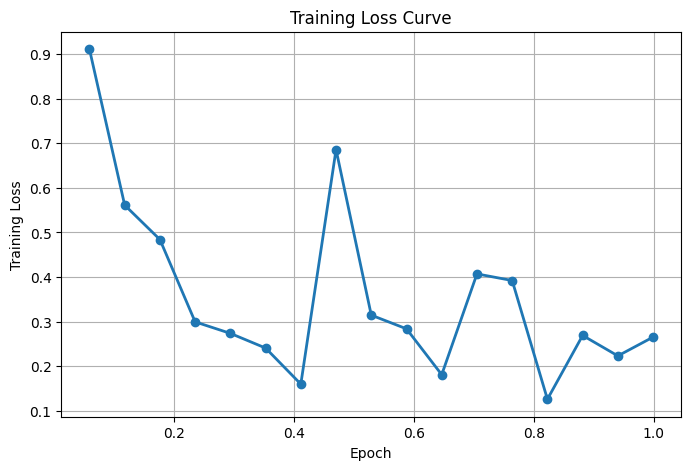

In [ ]:
import matplotlib.pyplot as plt

train_loss=[]
epochs=[]

for x in history:

    if "loss" in x:

        train_loss.append(x["loss"])
        epochs.append(x["epoch"])

plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    train_loss,
    marker='o',
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Curve")
plt.grid(True)

plt.show()

# Validation Loss Curve

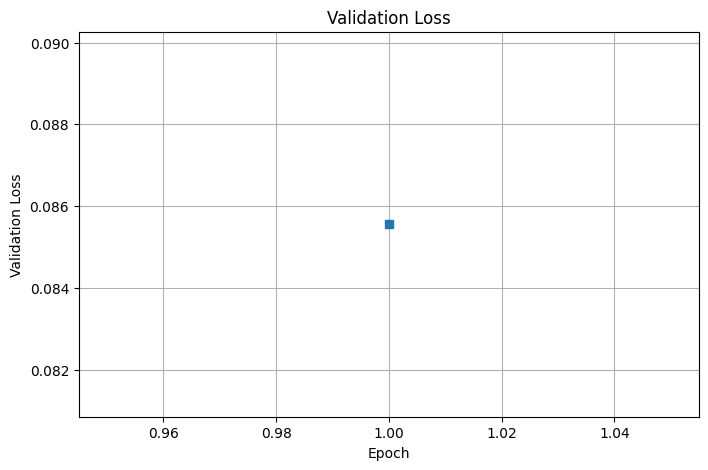

In [ ]:
eval_loss=[]
eval_epoch=[]

for x in history:

    if "eval_loss" in x:

        eval_loss.append(x["eval_loss"])
        eval_epoch.append(x["epoch"])

plt.figure(figsize=(8,5))

plt.plot(
    eval_epoch,
    eval_loss,
    marker='s',
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss")
plt.grid(True)

plt.show()

# STEP 8 — EVALUATION

Overall Accuracy: 0.9796610169491525
Accuracy  : 0.9797
Error Rate: 0.0203


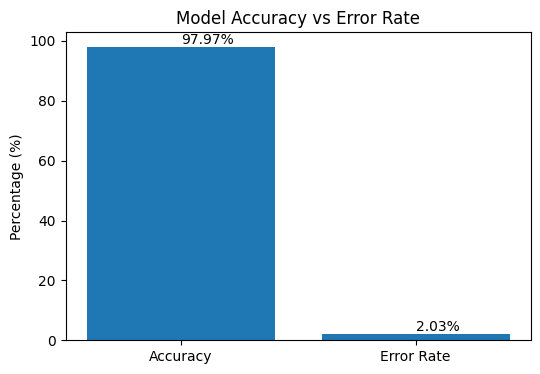


Overall Classification Report:
               precision    recall  f1-score   support

         ham       0.99      0.98      0.99      1054
        spam       0.96      0.97      0.96       421

    accuracy                           0.98      1475
   macro avg       0.97      0.98      0.98      1475
weighted avg       0.98      0.98      0.98      1475


Overall Confusion Matrix:
 [[1038   16]
 [  14  407]]

=== ENGLISH (n=1034) ===
Accuracy: 0.9912959381044487
              precision    recall  f1-score   support

         ham       1.00      0.99      1.00       903
        spam       0.96      0.97      0.97       131

    accuracy                           0.99      1034
   macro avg       0.98      0.98      0.98      1034
weighted avg       0.99      0.99      0.99      1034


=== BANGLA (n=441) ===
Accuracy: 0.9523809523809523
              precision    recall  f1-score   support

         ham       0.93      0.93      0.93       151
        spam       0.96      0.97      0.

In [ ]:
# Get predictions on the test set
predictions = trainer.predict(tokenized_test)
y_pred = predictions.predictions.argmax(axis=-1)
y_true = predictions.label_ids

print("Overall Accuracy:", accuracy_score(y_true, y_pred))


# Error Rate Graph

import matplotlib.pyplot as plt

# Accuracy
accuracy = accuracy_score(y_true, y_pred)

# Error Rate
error_rate = 1 - accuracy

print(f"Accuracy  : {accuracy:.4f}")
print(f"Error Rate: {error_rate:.4f}")

plt.figure(figsize=(6,4))

plt.bar(
    ["Accuracy", "Error Rate"],
    [accuracy*100, error_rate*100]
)

plt.ylabel("Percentage (%)")
plt.title("Model Accuracy vs Error Rate")

for i,v in enumerate([accuracy*100,error_rate*100]):
    plt.text(i,v+1,f"{v:.2f}%")

plt.show()
print("\nOverall Classification Report:\n", classification_report(y_true, y_pred, target_names=["ham", "spam"]))
print("\nOverall Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Per-language breakdown -- this is the part that actually tells you if the
# Bangla addition is working, since it's a minority of rows and an aggregate
# accuracy number could look fine while quietly hiding poor Bangla performance.
for lang, name in [("en", "ENGLISH"), ("bn", "BANGLA")]:
    mask = (test_df["lang"] == lang).to_numpy()
    print(f"\n=== {name} (n={mask.sum()}) ===")
    print("Accuracy:", accuracy_score(y_true[mask], y_pred[mask]))
    print(classification_report(y_true[mask], y_pred[mask], target_names=["ham", "spam"]))

# Confusion Matrix Heatmap

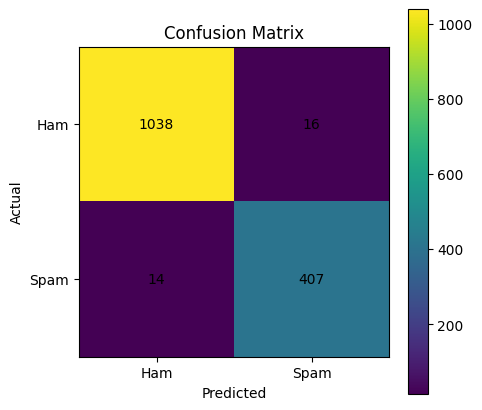

In [ ]:
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(5,5))

plt.imshow(cm)

plt.title("Confusion Matrix")

plt.colorbar()

plt.xticks([0,1],["Ham","Spam"])

plt.yticks([0,1],["Ham","Spam"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,str(cm[i,j]),
                 ha='center',
                 va='center')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

# Accuracy vs Error Rate Graph

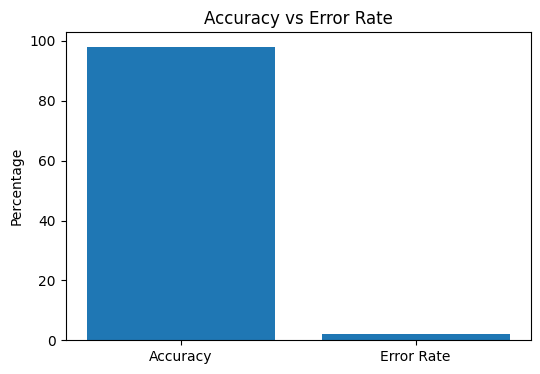

In [ ]:
accuracy = accuracy_score(y_true,y_pred)

error = 1-accuracy

plt.figure(figsize=(6,4))

plt.bar(
    ["Accuracy","Error Rate"],
    [accuracy*100,error*100]
)

plt.ylabel("Percentage")

plt.title("Accuracy vs Error Rate")

plt.show()

# Language-wise Accuracy

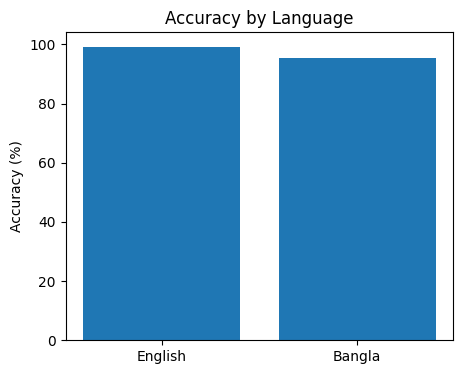

In [ ]:
langs=[]
accs=[]

for lang,name in [("en","English"),("bn","Bangla")]:

    mask=(test_df["lang"]==lang).to_numpy()

    acc=accuracy_score(y_true[mask],y_pred[mask])

    langs.append(name)

    accs.append(acc*100)

plt.figure(figsize=(5,4))

plt.bar(langs,accs)

plt.ylabel("Accuracy (%)")

plt.title("Accuracy by Language")

plt.show()

# Language-wise Error Rate

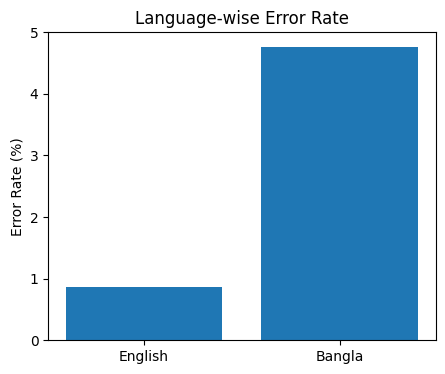

In [ ]:
langs=[]
errors=[]

for lang,name in [("en","English"),("bn","Bangla")]:

    mask=(test_df["lang"]==lang).to_numpy()

    acc=accuracy_score(y_true[mask],y_pred[mask])

    langs.append(name)

    errors.append((1-acc)*100)

plt.figure(figsize=(5,4))

plt.bar(langs,errors)

plt.ylabel("Error Rate (%)")

plt.title("Language-wise Error Rate")

plt.show()

# STEP 9 — PREDICTION FUNCTION

In [ ]:
def predict_email(text):

    # Move model to eval mode
    model.eval()

    # Tokenize input -- same tokenizer/model handle English or Bangla, no branching needed
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH, padding=True).to(model.device)

    # Inference
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)

        ham_prob = probs[0][0].item() * 100
        spam_prob = probs[0][1].item() * 100

        pred_idx = outputs.logits.argmax(dim=-1).item()
        label = "SPAM" if pred_idx == 1 else "HAM"



    print(f"Text: {text.strip()}")
    print("-" * 30)
    print("Prediction:", label)
    print(f"HAM Probability : {ham_prob:.2f}%")
    print(f"SPAM Probability: {spam_prob:.2f}%\n")

# STEP 10 — TEST (English + Bangla)

In [ ]:
predict_email("Free workshop registration is now available for students.")
predict_email("URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C")
predict_email("আপনার পার্সেল ডেলিভারির জন্য প্রস্তুত, রাইডার শীঘ্রই পৌঁছাবে।")
predict_email("অভিনন্দন! আপনি ৫০,০০০ টাকা জিতেছেন। এখনই ক্লেইম করুন: https://bkash-claim-prize.net/verify")

Text: Free workshop registration is now available for students.
------------------------------
Prediction: SPAM
HAM Probability : 0.01%
SPAM Probability: 99.99%

Text: URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C
------------------------------
Prediction: SPAM
HAM Probability : 0.00%
SPAM Probability: 100.00%

Text: আপনার পার্সেল ডেলিভারির জন্য প্রস্তুত, রাইডার শীঘ্রই পৌঁছাবে।
------------------------------
Prediction: HAM
HAM Probability : 100.00%
SPAM Probability: 0.00%

Text: অভিনন্দন! আপনি ৫০,০০০ টাকা জিতেছেন। এখনই ক্লেইম করুন: https://bkash-claim-prize.net/verify
------------------------------
Prediction: SPAM
HAM Probability : 0.00%
SPAM Probability: 100.00%

